# Basic Training Models

This notebook uses a small made-up table to predict `y` from `x`. I split the rows first, try a few simple models, and save the test rows for the very end.


## Step 1 - Import the Tools

NumPy holds numbers and does the math. Pandas holds the table. Matplotlib draws the pictures. Scikit-learn gives me models I can compare. RMSE is the typical size of my mistakes, in the same units as `y`. Those units are made up for this class file.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, learning_curve
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.base import clone

def rmse(actual, predicted):
    return mean_squared_error(actual, predicted) ** 0.5


## Step 2 - Load the Data

I split the file before I study the dots or pick a model. The first split saves 20% for the final test. The second split takes 25% of what is left. That piece is another 20% of the whole file, so I get about 60% to train, 20% to compare models, and 20% for the final test. Each row keeps its x and y together. I will not look at the test rows while I choose a model.


In [2]:
df = pd.read_csv('training_models_demo.csv')
X = df[['x']].to_numpy()
y = df['y'].to_numpy()
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=42)
print('Train / validation / test:',
      len(X_train), len(X_valid), len(X_test))


Train / validation / test: 144 48 48


The split is 144 training rows, 48 validation rows, and 48 test rows.


## Step 3 - Explore the Training Data

I only look at the training rows here. I want the data types, any blank spots, the spread of the numbers, and the shape of the dots.


          x          y
0  2.824188  10.522462
1 -0.265342   3.016801
2 -0.246505   1.539071
3  1.094973   4.775298
4  1.433904   5.261035
<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       144 non-null    float64
 1   y       144 non-null    float64
dtypes: float64(2)
memory usage: 2.4 KB
Missing values:
x    0
y    0
dtype: int64
            x       y
count  144.00  144.00
mean    -0.08    3.73
std      1.75    2.73
min     -2.92   -0.14
25%     -1.73    1.75
50%     -0.19    2.93
75%      1.45    5.16
max      2.95   10.90


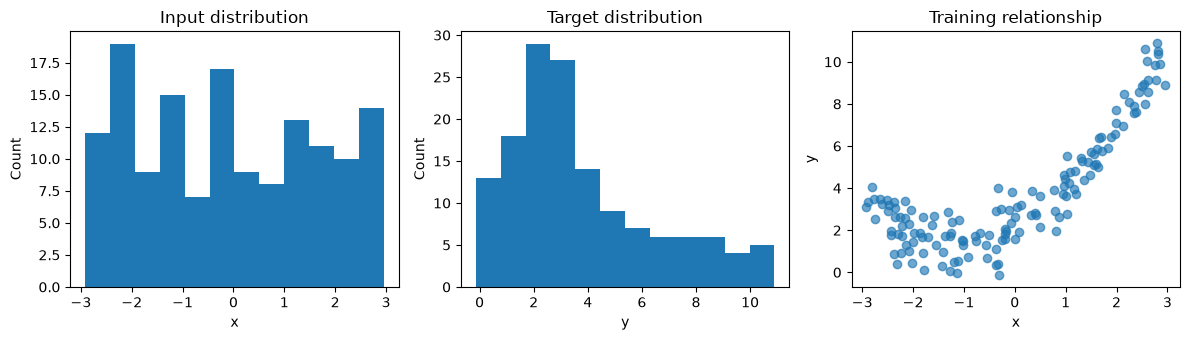

In [3]:
train_df = pd.DataFrame({'x': X_train[:, 0], 'y': y_train})
print(train_df.head())
train_df.info()
print('Missing values:')
print(train_df.isna().sum())
print(train_df.describe().round(2))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].hist(train_df['x'], bins=12)
axes[0].set(xlabel='x', ylabel='Count', title='Input distribution')
axes[1].hist(train_df['y'], bins=12)
axes[1].set(xlabel='y', ylabel='Count', title='Target distribution')
axes[2].scatter(X_train[:, 0], y_train, alpha=0.65)
axes[2].set(xlabel='x', ylabel='y', title='Training relationship')
plt.tight_layout()
plt.show()


Both columns are plain numbers, and nothing is missing. On the training rows, x goes from about -2.92 to 2.95, and y goes from about -0.14 to 10.90. The dots make a curve. They sit lower around the middle and climb when x gets large, so a straight line would miss that bend. My guess is that a model that can curve will fit better than a straight line.


## Step 4 - Make a Mean Baseline

A baseline ignores x and always guesses the training average. I use only the training average so the later check stays fair. If I used every row, that average would peek at answers I am saving for the end. Resizing x has the same rule. If that step saw the test rows, it would learn from them too soon. The first column is all ones. That column lets one weight learn a starting height. The second column is scaled x, so the other weight is the slope for one normal step of x.


In [4]:
mean_prediction = float(y_train.mean())
baseline_train = np.full(len(y_train), mean_prediction)
baseline_valid = np.full(len(y_valid), mean_prediction)
print('Training mean:', round(mean_prediction, 3))
print('Baseline train RMSE:', round(rmse(y_train, baseline_train), 3))
print('Baseline valid RMSE:', round(rmse(y_valid, baseline_valid), 3))
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_valid_s = scaler.transform(X_valid)
Xb_train = np.c_[np.ones(len(X_train_s)), X_train_s]
Xb_valid = np.c_[np.ones(len(X_valid_s)), X_valid_s]
print('Design matrix:', Xb_train.shape)


Training mean: 3.734
Baseline train RMSE: 2.722
Baseline valid RMSE: 2.702
Design matrix: (144, 2)


The training mean is about 3.734. Always guessing that number gives a training RMSE of about 2.722 and a validation RMSE of about 2.702. A useful model should beat those scores. The design matrix has 144 rows and 2 columns, and the first column is all ones.


## Step 5 - Write Batch Gradient Descent

Each update does a few small jobs. `Xb @ theta` guesses y for every row. Subtracting `target` shows how far each guess is from the real y. `(2 / len(target)) * Xb.T @ errors` looks at every training row and says which way each weight should move so the mistakes get smaller. `theta = theta - rate * gradient` takes a small step that way. If one part of the gradient is positive, subtracting it makes that weight smaller.


In [5]:
def train_gd(Xb, target, rate=0.1, epochs=100):
    theta = np.zeros(Xb.shape[1])
    losses = []
    for epoch in range(epochs):
        errors = Xb @ theta - target
        gradient = (2 / len(target)) * Xb.T @ errors
        theta = theta - rate * gradient
        loss = np.mean((Xb @ theta - target) ** 2)
        losses.append(loss)
        if not np.isfinite(loss) or loss > 1e12:
            break  # stop an intentionally unstable experiment
    return theta, np.array(losses)

theta_gd, losses = train_gd(Xb_train, y_train)
print('Intercept and scaled slope:', theta_gd.round(3))
print('First / last MSE:', losses[[0, -1]].round(3))
print('Validation RMSE:', round(rmse(y_valid, Xb_valid @ theta_gd), 3))


Intercept and scaled slope: [3.734 2.171]
First / last MSE: [14.637  2.694]
Validation RMSE: 1.96


The run finished all 100 steps. The training error started at 14.637 and ended at 2.694, so the steps went downhill. The two weights are about 3.734 and 2.171. Validation RMSE is 1.96, which beats the baseline. The slope is for scaled x, not for one plain unit of x. A straight line still cannot follow the curve in the dots.


## Step 6 - Try Different Learning Rates

A lower training loss does not prove I picked a flexible enough model. It only means this one model is getting closer on the training rows. A straight line can improve and still miss a curve. I still need the picture of the dots and a validation score.


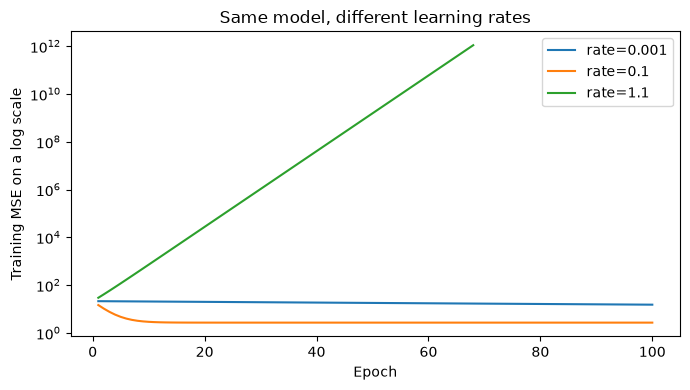

In [6]:
plt.figure(figsize=(7, 4))
for rate in [0.001, 0.1, 1.1]:
    trial_theta, trial_loss = train_gd(
        Xb_train, y_train, rate=rate, epochs=100
    )
    plt.semilogy(range(1, len(trial_loss) + 1), trial_loss,
                 label=f'rate={rate}')
plt.xlabel('Epoch')
plt.ylabel('Training MSE on a log scale')
plt.title('Same model, different learning rates')
plt.legend()
plt.tight_layout()
plt.show()


The tiny rate, 0.001, creeps down and is still high after 100 steps. The rate 0.1 drops quickly and levels off. The rate 1.1 shoots up and the loop stops early so the loss does not run away. These three rates are just for this demo.


## Step 7 - Compare with Least Squares

Gradient descent and least squares can land on almost the same straight line and both still miss the curve. They are solving the same straight-line job, so close weights mean my update math is working. A perfect straight line still cannot follow the curve in the data.


Least squares: [3.734 2.171]
Gradient descent: [3.734 2.171]
Largest parameter difference: 7.60707941083183e-10


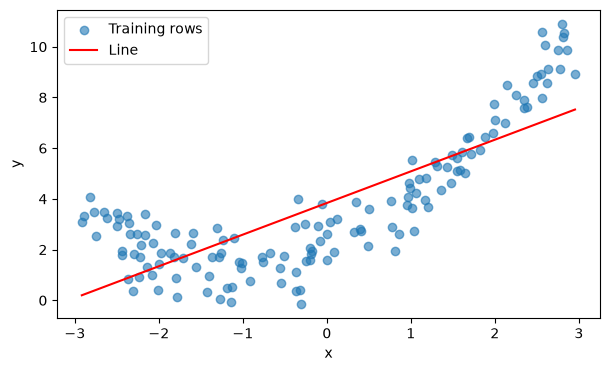

In [7]:
theta_ls = np.linalg.lstsq(Xb_train, y_train, rcond=None)[0]
print('Least squares:', theta_ls.round(3))
print('Gradient descent:', theta_gd.round(3))
print('Largest parameter difference:', np.max(np.abs(theta_ls - theta_gd)))
line_model = make_pipeline(StandardScaler(), LinearRegression())
line_model.fit(X_train, y_train)
grid = np.linspace(X_train.min(), X_train.max(), 200).reshape(-1, 1)
plt.figure(figsize=(7, 4))
plt.scatter(X_train[:, 0], y_train, alpha=0.6, label='Training rows')
plt.plot(grid[:, 0], line_model.predict(grid), color='red', label='Line')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()


The biggest gap between the two weight lists is much smaller than 0.000001, so they agree. The red line still leaves a curved gap around the dots.


## Step 8 - Compare Polynomial Models

A higher degree adds bends, such as x squared. The model builds those powers, resizes them, and then learns the weights. It does not add a second starting height. The model with the smallest training error does not have to be the model with the smallest validation error.


In [8]:
def polynomial_model(degree, alpha=0.0):
    estimator = LinearRegression() if alpha == 0 else Ridge(alpha=alpha)
    return make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(), estimator
    )

models = {}
rows = []
for degree in [1, 2, 10]:
    fitted = polynomial_model(degree).fit(X_train, y_train)
    models[degree] = fitted
    rows.append({'degree': degree,
                 'train_rmse': rmse(y_train, fitted.predict(X_train)),
                 'valid_rmse': rmse(y_valid, fitted.predict(X_valid))})
comparison = pd.DataFrame(rows)
print(comparison.round(3))


   degree  train_rmse  valid_rmse
0       1       1.641       1.960
1       2       0.797       0.772
2      10       0.767       0.791


Degree 10 has the smallest training RMSE, about 0.767. Degree 2 has the smallest validation RMSE, about 0.772. The rankings differ because extra bends can chase wiggles in the training rows that do not show up in the validation rows. Degree 2 is much better than the straight line. Degree 10 is only a little worse than degree 2 on validation, so I need the table instead of guessing that a high degree must fail.


## Step 9 - Read Learning Curves

If both lines are close and both are high, the model is too simple. It does poorly on old rows and on new rows. If the training line is low and the other line is much higher, the model memorized the training rows. These lines use only the training rows, split three ways. The bottom axis is how many rows we use. The scores start out negative, so the code flips them before the square root. That turns them into normal error sizes.


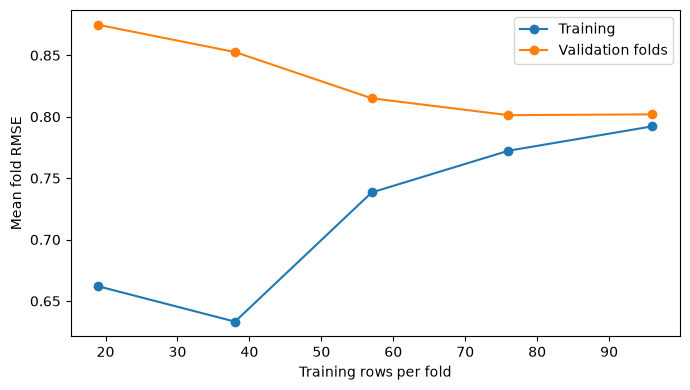

In [9]:
cv = KFold(n_splits=3, shuffle=True, random_state=42)
sizes, train_scores, valid_scores = learning_curve(
    polynomial_model(2), X_train, y_train, cv=cv,
    train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0],
    scoring='neg_mean_squared_error')
train_errors = np.sqrt(-train_scores).mean(axis=1)
valid_errors = np.sqrt(-valid_scores).mean(axis=1)
plt.figure(figsize=(7, 4))
plt.plot(sizes, train_errors, 'o-', label='Training')
plt.plot(sizes, valid_errors, 'o-', label='Validation folds')
plt.xlabel('Training rows per fold')
plt.ylabel('Mean fold RMSE')
plt.legend()
plt.tight_layout()
plt.show()


With only a few rows, training error looks smaller and validation error is higher. As more rows are added, validation error comes down and the two lines get closer, around 0.8. That gap is small. The biggest group on this plot is 96 rows, not all 144, because each split holds some rows back.


## Step 10 - Prepare Ridge Candidates

Before I score the choices, my guess is that a bigger alpha pulls the weights toward zero. Training error will usually go up because the model is less free. Validation error might get a little better if a wiggly model was copying random bumps. A very big alpha can make validation error worse by making the model too stiff. The error I print is still the plain size of the misses. I will keep the test rows closed while I compare these six settings.


In [10]:
candidate_settings = [(1, 0.0), (2, 0.0), (10, 0.0),
                      (10, 0.1), (10, 1.0), (10, 10.0)]
print('Candidates (degree, alpha):', candidate_settings)
# alpha=0 uses LinearRegression. Positive alpha uses Ridge.
# Keep the test set closed while comparing these candidates.


Candidates (degree, alpha): [(1, 0.0), (2, 0.0), (10, 0.0), (10, 0.1), (10, 1.0), (10, 10.0)]


There are six choices. Alpha 0 is a plain fit. A positive alpha uses Ridge, which pulls big weights down. Each model still resizes the numbers before it learns.


## Step 11 - Choose a Model with Validation

I fit every candidate on the training rows and sort by validation RMSE. The top row is my recorded choice. I am still not using the test set.


In [11]:
results = []
for degree, alpha in candidate_settings:
    candidate = polynomial_model(degree, alpha).fit(X_train, y_train)
    results.append({'degree': degree, 'alpha': alpha,
                    'train_rmse': rmse(y_train, candidate.predict(X_train)),
                    'valid_rmse': rmse(y_valid, candidate.predict(X_valid))})
results = pd.DataFrame(results).sort_values('valid_rmse')
print(results.round(3).to_string(index=False))
best = results.iloc[0]
chosen_degree = int(best['degree'])
chosen_alpha = float(best['alpha'])
print('Recorded choice:', chosen_degree, chosen_alpha)


 degree  alpha  train_rmse  valid_rmse
     10    1.0       0.784       0.766
      2    0.0       0.797       0.772
     10    0.1       0.782       0.773
     10   10.0       0.821       0.785
     10    0.0       0.767       0.791
      1    0.0       1.641       1.960
Recorded choice: 10 1.0


The loss curves showed that 0.001 was slow, 0.1 settled, and 1.1 blew up. Nothing is missing in the training data, and the dots make a curve that is lower in the middle and higher on the right, so a straight line is too simple.

Degree 10 with alpha 0 did not win. It had the best training error, 0.767, but its validation error was 0.791. Making alpha bigger did not always help. Alpha 1.0 had the best validation score, and alpha 10 made both scores worse. Degree 2 with alpha 0 was very close, at 0.772.

I choose degree 10 and alpha 1.0 because that pair has the smallest validation error, 0.766. I am writing this choice down now, before I look at the test rows.


## Step 12 - Test the Frozen Choice Once

Getting the weights to settle told me the step size can walk downhill to a straight-line answer. It did not tell me that a straight line was the right shape. The test score tells me how far off the frozen model is on rows I never used for training or for picking settings. I will not change the model after I see this number.


Final test RMSE: 0.862
Frozen degree / alpha: 10 1.0


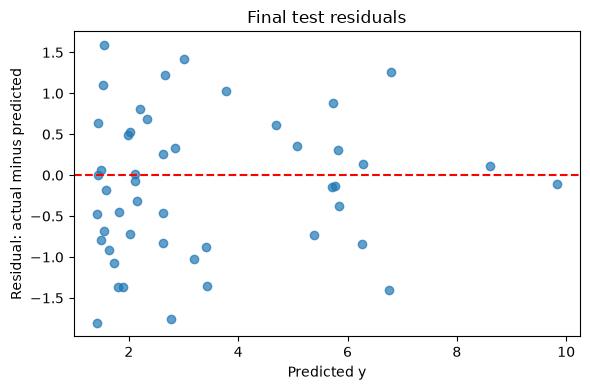

In [12]:
final_model = polynomial_model(chosen_degree, chosen_alpha)
final_model.fit(X_dev, y_dev)
test_predictions = final_model.predict(X_test)
print('Final test RMSE:', round(rmse(y_test, test_predictions), 3))
print('Frozen degree / alpha:', chosen_degree, chosen_alpha)
plt.figure(figsize=(6, 4))
plt.scatter(test_predictions, y_test - test_predictions, alpha=0.7)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted y')
plt.ylabel('Residual: actual minus predicted')
plt.title('Final test residuals')
plt.tight_layout()
plt.show()


The frozen choice is degree 10 and alpha 1.0. The final test RMSE is 0.862. The model learned from the 192 rows we kept for building and checking, then it was scored on the 48 test rows. The leftover dots sit around the red zero line. They are spread out, and I do not see a new clear curve, so I am not changing the model. This file is made-up class data, so this score does not prove the model would work on real measurements. Guessing y for x values far outside this file would also be a stretch.
